Here is a simple example code for device fitting using a multilayer perceptron model.
This code demonstrates the implementation of a Multilayer Perceptron (MLP) using PyTorch, a popular deep learning framework. Let's break down the key components of this code.

In [1]:
import os
import sys
import json

import torch
import torch.nn as nn
from torchvision import transforms, datasets, utils
import matplotlib.pyplot as plt
import numpy as np
import torch.optim as optim
from torch.optim.lr_scheduler import ReduceLROnPlateau
import pandas as pd
from tqdm import tqdm
import random

from torch.utils.data import TensorDataset, DataLoader

from model import MLP

This code defines a Multilayer Perceptron (MLP) neural network using PyTorch's nn.Module.
self.features defines the sequential layers of the neural network using nn.Sequential().
Here we define a 3-layer MLP.
nn.Linear(3, 30): The first layer consists of 3 input neurons and 30 neurons in the hidden layer. It performs a linear transformation (fully connected layer) from 3 input features to 30 neurons.
nn.ReLU(inplace=True): Applies a Rectified Linear Unit (ReLU) activation function to introduce non-linearity after the first linear transformation.
nn.Linear(30, 10): The second layer comprises 30 input neurons and 10 neurons in the hidden layer, followed by another ReLU activation.
nn.Linear(10,1): The final layer has 10 input neurons and 1 output neuron, producing the final output of the MLP.

The forward method defines the forward pass through the network.

In [2]:
class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()
        self.features = nn.Sequential(
            nn.Linear(3, 30), # 3 input, first layer 30 neurons, using linear transformation
            nn.ReLU(inplace=True),
            nn.Linear(30, 10),  # second layer 10 neurons using rectified linear unit
            nn.ReLU(inplace=True),
            nn.Linear(10,1), # 1 output reduce to the final output
        )


    def forward(self, x):
        x = self.features(x)
        x = x.squeeze(-1)
        return x

The code snippet demonstrates the selection of the computational device for running the MLP (Multilayer Perceptron) network.
Device Allocation:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu"): This line of code assigns the computational device to the variable device. If a GPU is available, it selects the GPU (cuda:0); otherwise, it defaults to the CPU (cpu).
Printing Device Information:
print("using {} device.".format(device)): This prints a message indicating the device being utilized for computation.

In [3]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("using {} device.".format(device))

using cpu device.


The code snippet demonstrates reading data from an Excel file into a Python environment using the Pandas library.
Excel File Import:
excel_file = '../data/carbon/pfet.xlsx': Specifies the file path (pfet.xlsx) of the Excel file containing the data.
Pandas DataFrame Creation:
df = pd.read_excel(excel_file): Utilizes Pandas' read_excel function to load the Excel file into a Pandas DataFrame named df. This function reads the Excel file's contents and stores them in a tabular format.
Data Verification:
print(df.head()): Displays the first few rows of the loaded DataFrame using the head() method. This step helps verify the successful import of data by showing the initial rows of the DataFrame, ensuring that the data is correctly read and structured.

In [4]:
#Excel File Import
excel_file = 'nfet_ids_vds.xlsx'
df = pd.read_excel(excel_file)

print(df.head())

    vds  vgs    lg           ids
0  0.00  0.0  0.25 -2.120430e-10
1  0.02  0.0  0.25  3.188530e-08
2  0.04  0.0  0.25  5.823670e-08
3  0.06  0.0  0.25  8.871480e-08
4  0.08  0.0  0.25  1.089610e-07


This code snippet focuses on data preparation steps necessary before training the Multilayer Perceptron (MLP) model.
Input and Output Extraction:
Specifies the columns representing input features based on their column names in the dataset.
Defines the output column ('ids') indicating the target output (e.g., current) from the dataset.
Conversion to PyTorch Tensors:
Converts the selected input columns and output column into PyTorch tensors. This step transforms the input data into a format suitable for feeding into the neural network.
Data Transformation:
Take the logarithm of the output data to narrow the data range. This transformation might be employed to normalize or preprocess the output data, ensuring better convergence during training or meeting specific requirements of the model.

In [5]:

# Extract input and output columns
input_columns = ['vds', 'vgs', 'lg']
output_column = 'ids'
# Converts into PyTorch tensors
X = torch.tensor(df[input_columns].values, dtype=torch.float32)
Y = torch.tensor(df[output_column].values, dtype=torch.float32)
# Take the logarithm of the output data
Y = -0.1 * torch.where(Y < 0, torch.log(-Y), torch.log(Y))
# Here print the input and output separately
print(X)
print(Y)

tensor([[0.0000, 0.0000, 0.2500],
        [0.0200, 0.0000, 0.2500],
        [0.0400, 0.0000, 0.2500],
        ...,
        [2.9600, 4.4000, 1.0000],
        [2.9800, 4.4000, 1.0000],
        [3.0000, 4.4000, 1.0000]])
tensor([2.2274, 1.7261, 1.6659,  ..., 0.7531, 0.7534, 0.7528])


This section of the code snippet focuses on partitioning the available data into separate sets for training and testing the MLP (Multilayer Perceptron) model.
Splitting the Dataset:
These calculations aim to appropriately divide the dataset into two distinct portions:
Training Set: Comprising 90% of the data, reserved for training the MLP model. It includes input-output pairs used to optimize the model's parameters.
Testing Set: Consisting of the remaining 10% of the data. This set remains unseen during training and is employed solely for evaluating the model's performance on unseen data, assessing its generalization capability.

In [6]:
 # Divide the data into training set and test set
train_size = int(0.9 * len(X))
test_size = len(X) - train_size

This part of the code is responsible for constructing specific datasets—both for training and testing the MLP (Multilayer Perceptron) model.
Constructs the training dataset and forms the testing dataset (test_dataset) by packing the remaining input-output pairs not included in the training set.

In [7]:
# Construct the training dataset and testing dataset
train_dataset = TensorDataset(X[:train_size], Y[:train_size])
train_num = len(train_dataset)
test_dataset = TensorDataset(X[train_size:], Y[train_size:])
test_num = len(test_dataset)

This section of the code focuses on setting up data loaders, essential components used to manage and facilitate the training and testing processes within the MLP.
Defining Batch Size:
batch_size = 32: Specifies the batch size, indicating the number of samples that the model will process in each iteration during training or testing. It's a hyperparameter selected to balance computational efficiency and model learning.
Creating Training Data Loader:
Constructs a training data loader (train_loader) using PyTorch's DataLoader. This loader takes the previously created training dataset (train_dataset) and organizes it into batches of size batch_size. The shuffle=True parameter randomly shuffles the samples within each batch, enhancing model learning by providing diverse sample sequences.
Creating Testing Data Loader:
Constructs a testing data loader (test_loader) in a similar manner to the training loader. It takes the testing dataset (test_dataset) and organizes it into batches of the specified batch_size.

In [8]:
# creating data loader
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

print("using {} data for training, {} data for validation.".format(train_num,test_num))


using 4620 data for training, 514 data for validation.


This section of the code focuses on initializing the MLP (Multilayer Perceptron) network, configuring it for device compatibility, defining the loss function, and setting up the optimizer for training.
MLP Network Initialization:
net = MLP(): Instantiates the MLP model (net) by calling the defined MLP class.
Device Allocation:
net.to(device): Transfers the MLP model (net) to the specified device (e.g., GPU if available, otherwise CPU).
Loss Function Definition:
Defines the loss function (MSELoss) as Mean Squared Error (MSE) or RMSE, which quantifies the disparity between the predicted and actual values in the dataset. It provides a measure of the model's performance during training.
Optimizer Initialization:
Sets up the optimizer (Adam optimizer) responsible for adjusting the model's parameters to minimize the defined loss. It optimizes the network's weights (net.parameters()) based on the computed gradients and a specified learning rate (lr=0.002), aiding in convergence towards optimal model parameters.

In [9]:
net = MLP()

net.to(device)
loss_function = nn.MSELoss(reduction="mean")
optimizer = optim.Adam(net.parameters(), lr=0.002)

This section of the code oversees the training and validation processes for the MLP (Multilayer Perceptron) network. It iterates through multiple epochs, computes losses, updates model parameters, and evaluates model performance on a validation dataset.
Training Loop (Epoch Iterations):
epochs = 200: Specifies the number of epochs, representing the complete passes through the entire training dataset during model training.
During Training Phase:
The outer loop (for epoch in range(epochs)) iterates over each epoch.
For each mini-batch in the training set, it performs forward and backward passes:
Obtains input and target data from the current mini-batch. And computes predictions (outputs) using the MLP model (net).
Calculates the loss (Root Mean Squared Error - RMSE) between predicted and target values.
Updates the model's parameters by backpropagating the loss and applying optimization via the defined optimizer.
Validation Phase:
After each epoch's training, the code proceeds to the validation phase by iterating through the validation dataset (test_loader).
It evaluates the model's performance on the validation set, computing the RMSE between predicted and target values.
Calculates the average RMSE across the entire validation dataset (val_mse) to assess model performance.
Model Saving:
Throughout training, the code saves the model's parameters to a specified path (save_path = './MLP.pth') after each epoch.

In [10]:
import matplotlib.pyplot as plt

epochs = 100
save_path = './MLP.pth'
best_acc = 0.0
train_steps = len(train_loader)
val_mse_list = []  # List to store val_mse values

for epoch in range(epochs):
    # train
    running_loss = 0.0
    train_bar = tqdm(train_loader, file=sys.stdout)
    for step, data in enumerate(train_bar):
        input_vari, output_tar = data
        optimizer.zero_grad()
        outputs = net(input_vari.to(device))
        loss = torch.sqrt(loss_function(outputs, output_tar.to(device)))
        loss.backward()
        optimizer.step()

        # print statistics
        running_loss += loss.item()

        train_bar.desc = "train epoch[{}/{}] loss:{:.3f}".format(epoch + 1, epochs, loss)
    
    # validate
    acc = 0.0  # accumulate accurate number / epoch
    mse_sum = 0.0
    with torch.no_grad():
        val_bar = tqdm(test_loader, file=sys.stdout)
        for val_data in val_bar:
            val_input, val_output = val_data
            outputs = net(val_input.to(device))
            mse = torch.sqrt(loss_function(outputs, val_output.to(device)))
            mse_sum += mse

    val_mse = mse_sum / test_num
    val_mse_list.append(val_mse.item())  # Store val_mse value
    print('[epoch %d] train_loss: %.3f  val_mse: %.6f' %
          (epoch + 1, running_loss / train_steps, val_mse))

    torch.save(net.state_dict(), save_path)



100%|██████████| 17/17 [00:00<00:00, 650.29it/s]
[epoch 1] train_loss: 0.321  val_mse: 0.002185
100%|██████████| 17/17 [00:00<00:00, 768.77it/s]
[epoch 2] train_loss: 0.088  val_mse: 0.001751
100%|██████████| 17/17 [00:00<00:00, 1829.18it/s]
[epoch 3] train_loss: 0.074  val_mse: 0.001505
100%|██████████| 17/17 [00:00<00:00, 966.25it/s]
[epoch 4] train_loss: 0.066  val_mse: 0.001538
100%|██████████| 17/17 [00:00<00:00, 1881.10it/s]
[epoch 5] train_loss: 0.059  val_mse: 0.001756
100%|██████████| 17/17 [00:00<00:00, 1210.03it/s]
[epoch 6] train_loss: 0.055  val_mse: 0.001925
100%|██████████| 17/17 [00:00<00:00, 1414.44it/s]
[epoch 7] train_loss: 0.051  val_mse: 0.001617
100%|██████████| 17/17 [00:00<00:00, 1075.17it/s]
[epoch 8] train_loss: 0.049  val_mse: 0.002523
100%|██████████| 17/17 [00:00<00:00, 1379.71it/s]
[epoch 9] train_loss: 0.047  val_mse: 0.001609
100%|██████████| 17/17 [00:00<00:00, 614.64it/s]
[epoch 10] train_loss: 0.046  val_mse: 0.001623
100%|██████████| 17/17 [00:00<00:

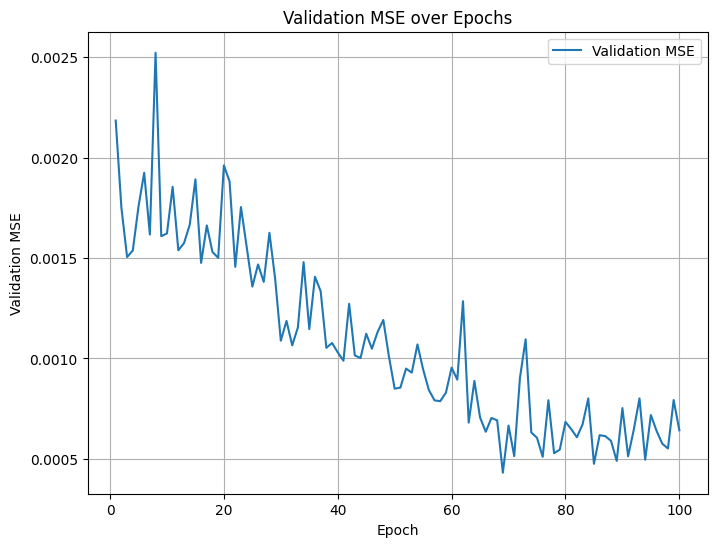

In [11]:
# Plot the change of val_mse over epochs
plt.figure(figsize=(8, 6))
plt.plot(range(1, epochs + 1), val_mse_list, label='Validation MSE')
plt.xlabel('Epoch')
plt.ylabel('Validation MSE')
plt.title('Validation MSE over Epochs')
plt.legend()
plt.grid(True)
plt.show()